# Решающие деревья

#  I. Немного решающих деревьев
##### Задача 1. Построение "среднего" алгоритма
В этом задании вам нужно построить графики, демонстрирующие, как алгоритм аппроксимирует истинную зависимость в данных и как он меняется в зависимости от гиперпараметров метода обучения.

In [ ]:
from matplotlib import pyplot as plt
%matplotlib inline

<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\s'
C:\Users\vyach\AppData\Local\Temp\ipykernel_11040\4116343271.py:18: SyntaxWarning: invalid escape sequence '\s'
  label='Истинная зависимость $f(x) = \sin(x)$',


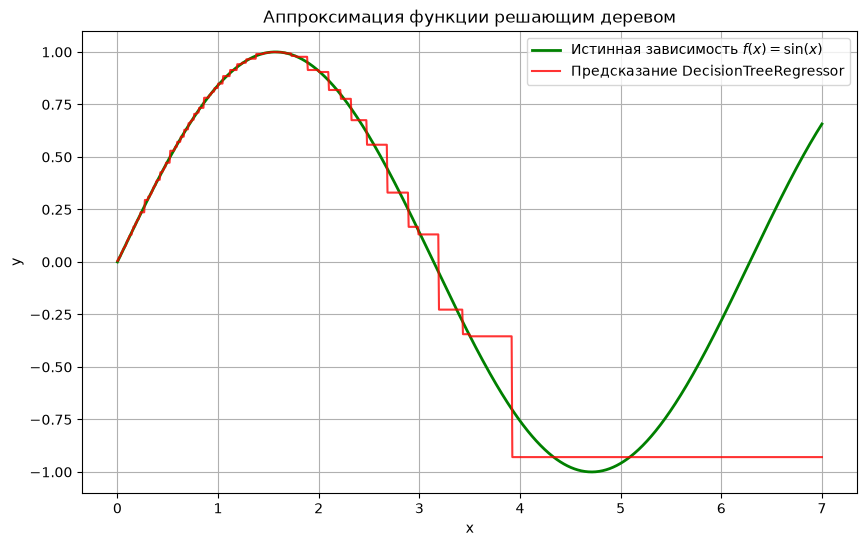

In [5]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.tree import DecisionTreeRegressor
def f(x):
    return np.sin(x)
sample_size = 100#определяем функции и параметры
linspace = np.linspace(0, 7, 1000)
np.random.seed(42)
X = np.random.exponential(size=sample_size)#100 рандомных точек на х
y = f(X)
tree = DecisionTreeRegressor()
tree.fit(X[:, np.newaxis], y)#обучение модели
y_pred = tree.predict(linspace[:, np.newaxis])#сделаем все предсказания
plt.figure(figsize=(10, 6))
plt.plot(
    linspace,
    f(linspace),
    label='Истинная зависимость $f(x) = \sin(x)$',
    color='green',
    linewidth=2,
)
plt.plot(
    linspace,
    y_pred,
    label='Предсказание DecisionTreeRegressor',
    color='red',
    alpha=0.8,
)
plt.title('Аппроксимация функции решающим деревом')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

__1. (2 балла)__
1. Сгенерируйте выборку $x$ из одномерного экспоненциального распределения (np.random.exponential) длины sample_size.
1. Создайте вектор целевых переменных $y$ как сумму $f(x)$ и случайного шума, сгенерированного из равномерного распределения на отрезке $[-1, 1]$ (np.random.uniform).
1. Обучите DecisionTreeRegressor с параметрами по умолчанию на полученной выборке и сделайте предсказания для объектов из linspace.
1. Постройте два графика на одном рисунке: $f(x)$ и зависимость, восстановленную решающим деревом.

    Рекомендация: не забудьте, что все методы обучения в sklearn требуют на вход двумерную матрицу объекты-признаки. Сделать такую из одномерного вектора можно добавлением мнимых осей (np.newaxis).

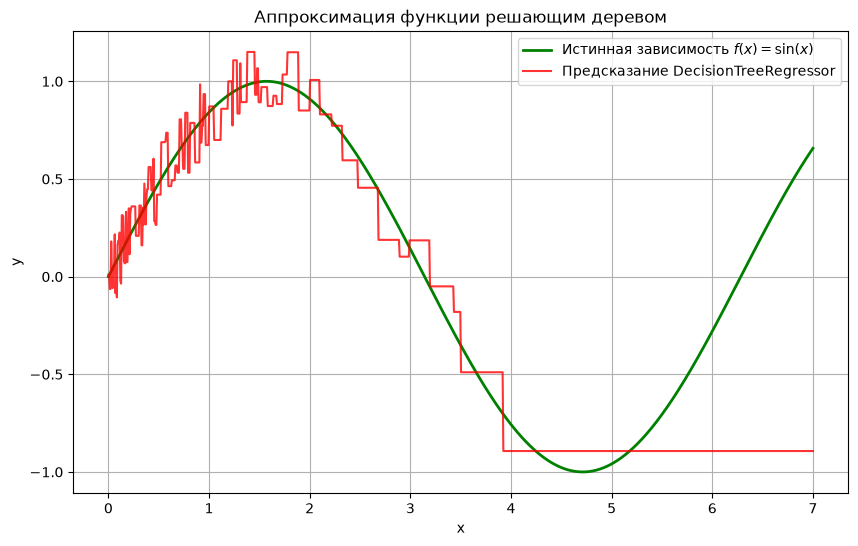

In [6]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.tree import DecisionTreeRegressor
def f(x):
    return np.sin(x)
sample_size = 100
linspace = np.linspace(0, 7, 1000)
np.random.seed(42)
X = np.random.exponential(size=sample_size)
y = f(X) + np.random.uniform(low=-0.2, high=0.2, size=sample_size)#генерация шума
tree = DecisionTreeRegressor()
tree.fit(X[:, np.newaxis], y)
y_pred = tree.predict(linspace[:, np.newaxis])
plt.figure(figsize=(10, 6))
plt.plot(
    linspace,
    f(linspace),
    label='Истинная зависимость $f(x) = \\sin(x)$',
    color='green',
    linewidth=2,
)
plt.plot(
    linspace,
    y_pred,
    label='Предсказание DecisionTreeRegressor',
    color='red',
    alpha=0.8,
)

plt.title('Аппроксимация функции решающим деревом')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

__2. (2 балл)__

Повторите первые 3 шага, описанные выше, samples_num раз. На одном графике для каждого обученного решающего дерева визуализируйте восстановленную им зависимость (рекомендуется все такие линии рисовать полупрозрачными и серым цветом: plt.plot(...... color="gray", alpha=0.5)).  На этом же графике изобразите истинную зависимость f(x) (красным цветом: color="red") и усредненную по всем деревьям восстановленную зависимость (черным цветом: color="black").    

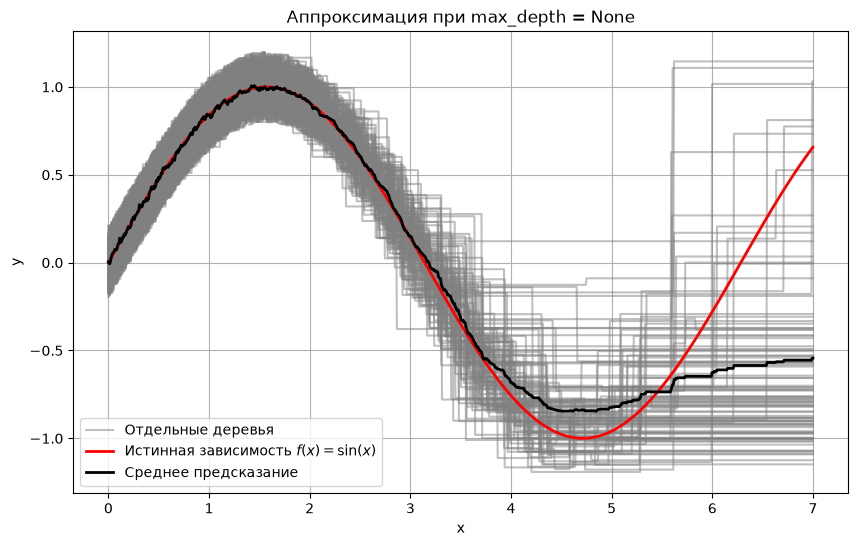

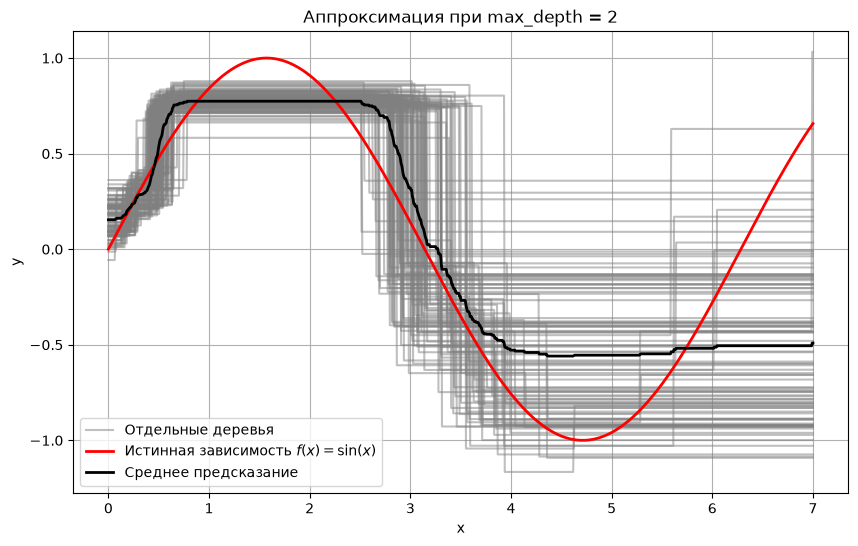

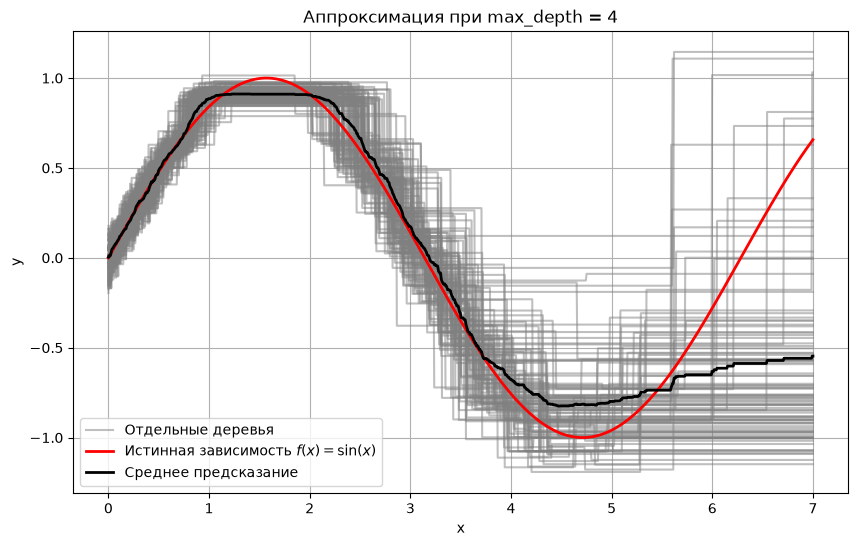

In [8]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.tree import DecisionTreeRegressor


def f(x):
    return np.sin(x)


sample_size = 100
samples_num = 100
linspace = np.linspace(0, 7, 1000)

def depth(a):
    np.random.seed(42)
    plt.figure(figsize=(10, 6))
    predictions = []

    for i in range(samples_num):
        X = np.random.exponential(size=sample_size)
        y = f(X) + np.random.uniform(low=-0.2, high=0.2, size=sample_size)
        tree = DecisionTreeRegressor(max_depth=a)#создаем модель решающего дерева
        tree.fit(X[:, np.newaxis], y)
        y_pred = tree.predict(linspace[:, np.newaxis])

        predictions.append(y_pred)
        plt.plot(
            linspace,
            y_pred,
            color='gray',
            alpha=0.5,
            label='Отдельные деревья' if i == 0 else '',
        )
    mean_pred = np.mean(predictions, axis=0)#усредненное предсказание по всем деревьям
    plt.plot(
        linspace,
        f(linspace),
        color='red',
        linewidth=2,
        label='Истинная зависимость $f(x) = \\sin(x)$',
    )

    plt.plot(
        linspace,
        mean_pred,
        color='black',
        linewidth=2,
        label='Среднее предсказание',
    )

    plt.title(f'Аппроксимация при max_depth = {a}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True)
    plt.show()


depth(None)
depth(2)
depth(4)

**Ответ:**

### II. Решающие деревья чужими руками

#### Задача 3.
В этой части вам нужно посмотреть на класс написанный за вас для обучения решающего дерева в задаче бинарной классификации с возможностью обработки вещественных и категориальных признаков.

__8. (1 балл)__

Загрузите таблицу [students.csv](https://drive.google.com/file/d/0B2zoFVYw1rN3a0d0Zm43TzQ4aUU/view?usp=sharing) (это немного преобразованный датасет [User Knowledge](https://archive.ics.uci.edu/ml/datasets/User+Knowledge+Modeling)). В ней признаки объекта записаны в первых пяти столбцах, а в последнем записана целевая переменная (класс: 0 или 1). Постройте на одном изображении пять кривых "порог — значение критерия Джини" для всех пяти признаков. Отдельно визуализируйте scatter-графики "значение признака — класс" для всех пяти признаков.

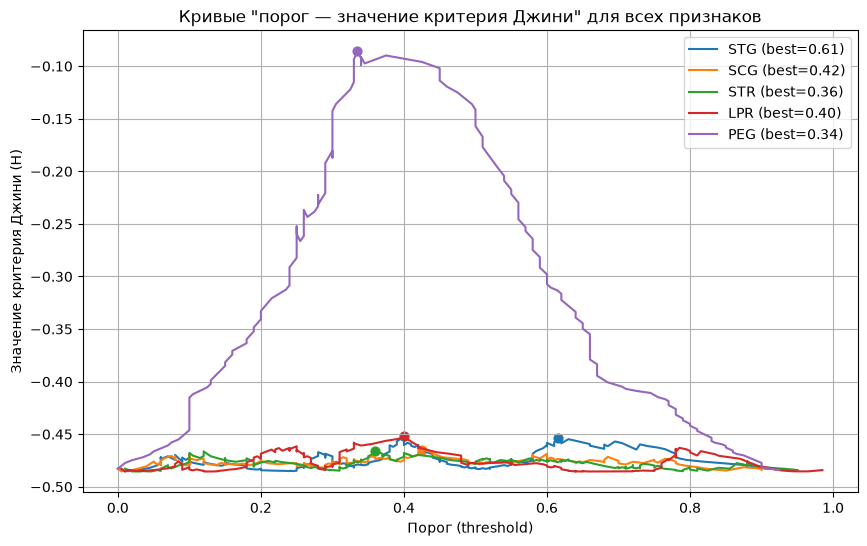

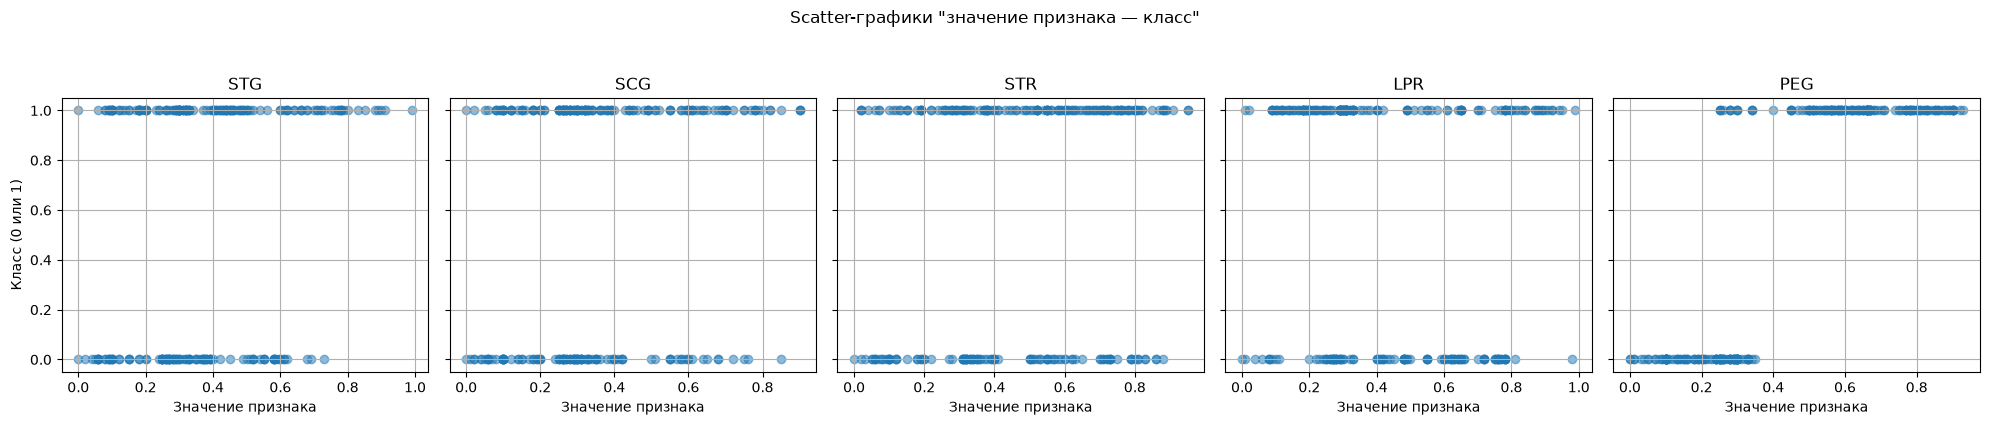

In [10]:
from importlib import reload
import hw3code
from matplotlib import pyplot as plt
import pandas as pd
reload(hw3code)
data = pd.read_csv('students.csv')

# Первые 5 столбцов — признаки, последний столбец — целевая переменная=> используем индекс [:-1]
features = data.columns[:-1]
target_col = data.columns[-1]
target_vector = data[target_col].values

plt.figure(figsize=(10, 6))
for feature in features:#находим все пороги разбиения и значения критерия Джини
    feature_vector = data[feature].values
    thresholds, ginis, threshold_best, gini_best = hw3code.find_best_split(
        feature_vector, target_vector
    )
    plt.plot(
        thresholds,
        ginis,
        label=f'{feature} (best={threshold_best:.2f})',
    )
    #  точка оптимального порога
    plt.scatter([threshold_best], [gini_best], s=40)

plt.title('Кривые "порог — значение критерия Джини" для всех признаков')
plt.xlabel('Порог (threshold)')
plt.ylabel('Значение критерия Джини (H)')
plt.legend()
plt.grid(True)
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for ax, feature in zip(axes, features):#создание ряда из пяти отдельных маленьких графиков
    ax.scatter(data[feature], data[target_col], alpha=0.5)
    ax.set_title(feature)
    ax.set_xlabel('Значение признака')
    ax.grid(True)

axes[0].set_ylabel('Класс (0 или 1)')
plt.suptitle('Scatter-графики "значение признака — класс"', y=1.05)
plt.tight_layout()
plt.show()

__9. (1 балл)__

Исходя из кривых значений критерия Джини, по какому признаку нужно производить деление выборки на два поддерева? Согласуется ли этот результат с визуальной оценкой scatter-графиков? Как бы охарактеризовали вид кривой для "хороших" признаков, по которым выборка делится почти идеально? Чем отличаются кривые для признаков, по которым деление практически невозможно?

**Ответ:индекс Джини показывает, насколько велика вероятность ошибиться, если случайному объекту из группы присвоить случайную метку класса согласно распределению классов в этой группе Минимальное значение (H = 0): достигается, когда узел идеально чистый, то есть все объекты в нём принадлежат только одному классу Максимальное значение: достигается, когда все классы представлены поровну 1)По какому признаку нужно производить деление выборки:
Деление выборки на два поддерева нужно производить по признаку PEG (последний из пяти признаков, означающий результат экзамена). На графике зависимости критерия Джини от порога именно для этого признака достигается наибольшее (максимальное) значение критерия (наиболее высокий пик в районе порога  0.34). 2)Да, согласуется. На scatter-графике «значение признака — класс» для признака PEG видно, что объекты классов 0 и 1 практически не перекрываются: почти все объекты класса 0 имеют значения признака меньше  0.34, а почти все объекты класса 1 — больше этого порога. Для остальных четырёх признаков (STG, SCG, STR, LPR) точки обоих классов сильно перемешаны по всей оси значений, поэтому провести чёткую границу невозможно. 3)Кривая для «хорошего» признака имеет ярко выраженный, чёткий глобальный экстремум Вдали от этого порога кривая монотонно убывает (или возрастает) к краевым значениям 4)Кривые для «плохих» (неинформативных) признаков выглядят пологими, «плоскими» или сильно зашумлёнными с множеством мелких локальных колебаний, без явного выраженного пика**

__10. (1 балл)__

Протестируйте свое решающее дерево на датасете [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom). Вам нужно скачать таблицу agaricus-lepiota.data (из [Data Folder](https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/)), прочитать ее с помощью pandas, применить к каждому столбцу LabelEncoder (из sklearn), чтобы преобразовать строковые имена категорий в натуральные числа. Первый столбец — это целевая переменная (e — edible, p — poisonous) Мы будем измерять качество с помощью accuracy, так что нам не очень важно, что будет классом 1, а что — классом 0. Обучите решающее дерево на половине случайно выбранных объектов (признаки в датасете категориальные) и сделайте предсказания для оставшейся половины. Вычислите accuracy.

У вас должно получиться значение accuracy, равное единице (или очень близкое к единице), и не очень глубокое дерево.

In [15]:
import hw3code
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

data = pd.read_csv('msh.csv', header=None)
le = LabelEncoder()
for col in data.columns:
    data[col] = le.fit_transform(data[col])
y = data.iloc[:, 0].values#забираем первый а потом до конца
X = data.iloc[:, 1:].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=42#делим данные пополам случайным образом
)
feature_types = ['categorical'] * X.shape[1]
tree = hw3code.DecisionTree(feature_types=feature_types)#признаки нужно обрабатывать как категориальные, а не как непрерывные числа
tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f'Accuracy на тестовой выборке: {acc:.4f}')

Accuracy на тестовой выборке: 0.9988


### IIII. Композиции деревьев
#### Задача 4. Сравнение композиционных методов над решающими деревьями
__11. (1 балл)__

Загрузите датасет из соревнования [BNP Paribas Cardif Claims Management](https://www.kaggle.com/c/bnp-paribas-cardif-claims-management/leaderboard). Возьмите из него первые 10к объектов, оставьте только вещественные признаки, а пропуски замените нулями. Разбейте выборку на обучение и контроль в соотношении 7:3.

1. С помощью cross_val_score с cv=3 оцените качество (accuracy) следующих классификаторов на обучающей выборке:
    * DecisionTreeClassifier
    * BaggingClassifier со 100 деревьями
    * RandomForestClassifier со 100 деревьями
    
Значение получается шумное, но в целом у вас должно получиться, что качество возрастает с каждым следующим алгоритмом (если это не так, то посмотрите как ведут себя алгоритмы с разными сидами в кроссвалидации и самих алгоритмах). Этот пример демонстрирует, что RandomForest — это более сложный алгоритм, чем бэггинг.

#### Задача 5. Число деревьев в случайном лесе
В этой задаче мы рассмотрим, переобучаются ли композиционные алгоритмы с увеличением числа деревьев.

__12. (1 балл)__

Переберите значения от 20 до 1000-5000 деревьев с шагом 20, посчитайте accuracy на тестовой выборке для каждого числа деревьев и постройте график зависимости качества от числа деревьев.

Рекомендация.

Если каждый раз обучать RandomForest с нуля, придётся обучить в общей сумме $20 + 200 + \ldots + 5000$ деревьев.
Однако, как мы знаем, деревья в случайных лесах строятся независимо и параллельно, поэтому можно обучить всего 5000 деревьев.

Для этого в при создании объекта класса RandomForestClassifier нужно указать в том числе warm_start=True. Затем обучить алгоритм с помощью метода fit, использовать метод predict для классификации. После этого с помощью метода set_params изменить параметр n_estimators. Если к полученному объекту применить метод fit, внутри него будет обучаться только недостающее число деревьев.

Переобучается ли случайный лес с увеличением числа деревьев?

In [ ]:
#code here